# **M507D Methods of Prediction**
# **Predicting Cannabis Use with a Neural Network**
**By Sunanda(GH1052812)**

**Problem statement:**

Prevention and health organizations have limited time and funds, and thus they must identify the high risk individuals of using cannabis and educate them at an earlier stage of their lives. The business value would be the ability of being able to detect high-risk individuals from readily available information at low cost such that limited resources can be used effectively. This data will be from an anonymous survey where details of individuals including demographics and ethnicity as well as personality traits are captured. These data will be collected by means of a questionnaire that an organization can undertake.

**Overview:**

The task at hand seeks to determine whether a person is cannabis user or not based solely on their demographics and personality scores. The dataset being used is an open-source survey where all the answers were mapped to numeric values, making the input data ready for a predictive model.

To consider the challenge as a binary classification task, whereby the target variable takes a value of **user** if the person has used cannabis within the past ten years, and **non-user** otherwise. In addressing the task, by developing several variants of a small neural network using Keras and Tensorflow, selecting the best performing one.

**About the data:**

Each row represents an anonymous survey participant. The input variables are five demographic factors (Age, Gender, Education, Country, Ethnicity) and seven personality traits. These personality traits are obtained using well-known questionnaires and correspond to Nscore(neuroticism),Escore(extraversion),Oscore(openness),Ascore(agreeableness),Cscore(conscientiousness),Impulsive(impulsiveness),SS(sensation seeking). Also, there is information about the last usage of some substances by the respondent, but the variable that is used in this model is just Cannabis.

**Plan of Notebook:**

Load data, create the target variable, explore data, clean data, create features, build neural net, perform several experiments to tune hyperparameters, train and evaluate the best model, select important features and conclude.


# **1. All Important Libraries**

This includes all the libraries which have been used for the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style("whitegrid")

# **2. Loading the Data**
Since there is no header in the file, so assign names to all the columns. There are total 32 columns in the dataset: 1 ID column, 5 background columns, 7 personality columns and most recently consumed drugs by the individual.

In [2]:
columns = ["ID", "Age", "Gender", "Education", "Country", "Ethnicity",
           "Nscore", "Escore", "Oscore", "Ascore", "Cscore", "Impulsive", "SS",
           "Alcohol", "Amphet", "Amyl", "Benzos", "Caff", "Cannabis", "Choc",
           "Coke", "Crack", "Ecstasy", "Heroin", "Ketamine", "Legalh", "LSD",
           "Meth", "Mushrooms", "Nicotine", "Semer", "VSA"]

data = pd.read_csv("drug_consumption.data", header=None, names=columns)
data.head(3)

,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,Ecstasy,Heroin,Ketamine,Legalh,LSD,Meth,Mushrooms,Nicotine,Semer,VSA
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0


The first line of data shown above gives an idea about the dataset. Background and Personality columns are stored as numeric values, whereas the drug columns contain the labels CL0 to CL6. The values might be strange looking as the survey creators have scaled down every variable, but the model only requires the difference between the people.

# **3. Create the Target**

The cannabis column uses seven labels from CL0 (never used) to CL6 (used today). Here, turn this into a single yes/no column: 1 if the person used cannabis within the last decade (CL2 to CL6) and 0 otherwise. Grouping the labels this way gives a clear, balanced split between people who use cannabis and people who do not, which is easier to model and to explain than seven separate classes.

In [3]:
user_labels = ["CL2", "CL3", "CL4", "CL5", "CL6"]
data["target"] = data["Cannabis"].isin(user_labels).astype(int)
data["target"].value_counts()

,count
target,
1,1265
0,620


# **4. Explore the Data**

It is essential to explore the data before creating the model. Here, it performs some basic data exploration including size check, missing values, duplicate check, and target balance and then visualize the relationship between variables and cannabis usage.

In [4]:
print("Rows & Columns:", data.shape)
print("Missing_Values:", data.isna().sum().sum())
print("Duplicate_Rows:", data.duplicated().sum())
print("User_Rate:", round(data["target"].mean(), 3))

Rows & Columns: (1885, 33)
Missing_Values: 0
Duplicate_Rows: 0
User_Rate: 0.671


/tmp/ipykernel_35082/1906507805.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=data, palette="Set2")


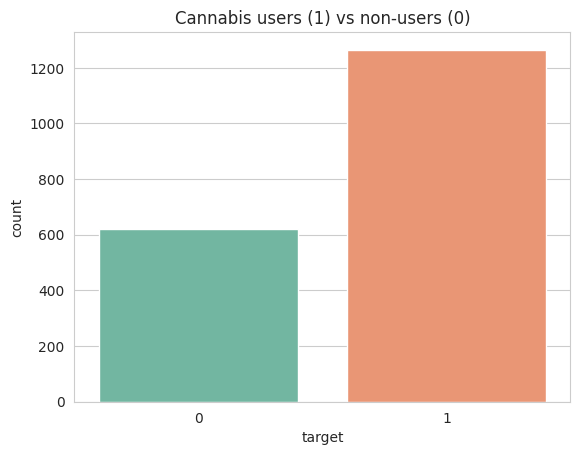

In [5]:
sns.countplot(x="target", data=data, palette="Set2")
plt.title("Cannabis users (1) vs non-users (0)")
plt.show()

The two categories are roughly balanced, so the model can learn from sufficient examples of each class.

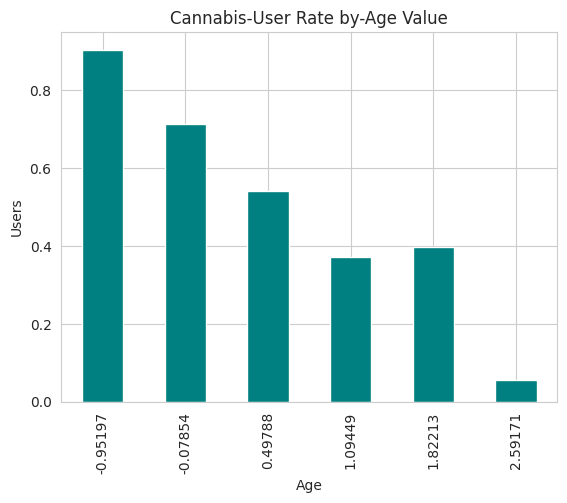

In [6]:
rate_by_age = data.groupby("Age")["target"].mean()
rate_by_age.plot(kind="bar", color="teal")
plt.title("Cannabis-User Rate by-Age Value")
plt.ylabel("Users")
plt.show()

From the graph above, it can be seen that the younger people are the respondents who are much more often cannabis users. The tendency grows old with age.

/tmp/ipykernel_35082/3409556628.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y=col, data=data, palette="Set2", ax=ax)
/tmp/ipykernel_35082/3409556628.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y=col, data=data, palette="Set2", ax=ax)
/tmp/ipykernel_35082/3409556628.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y=col, data=data, palette="Set2", ax=ax)


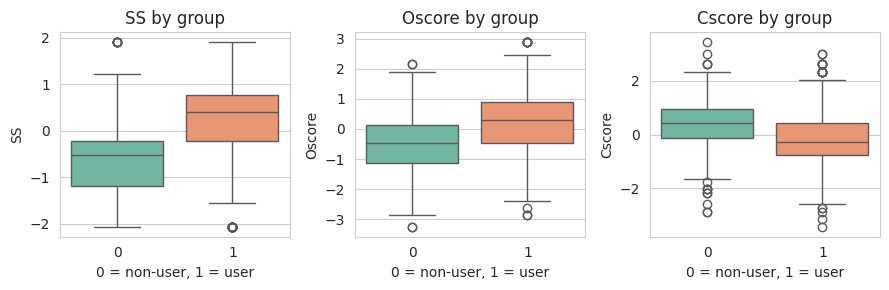

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, col in zip(axes, ["SS", "Oscore", "Cscore"]):
    sns.boxplot(x="target", y=col, data=data, palette="Set2", ax=ax)
    ax.set_title(col + " by group")
    ax.set_xlabel("0 = non-user, 1 = user")
plt.tight_layout()
plt.show()

**Users** score somewhat higher in sensation seeking and openness and lower in conscientiousness. There are some visible differences between users and non-users, but they are small and typical for surveys.

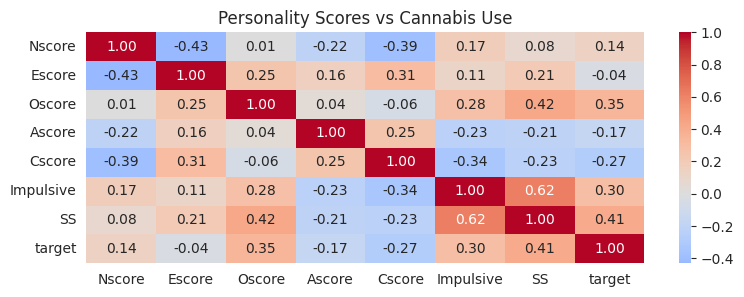

In [8]:
personality = ["Nscore", "Escore", "Oscore", "Ascore", "Cscore", "Impulsive", "SS"]
corr = data[personality + ["target"]].corr()
plt.figure(figsize=(9, 3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Personality Scores vs Cannabis Use")
plt.show()

They do not show that there is one decisive factor determining the use of drugs. In general, it can be said that SS, impulsiveness and Oscore are positively correlated with the usage of drugs, and Cscore is negatively related to it.

# **5. Cleaning the Data**

The survey includes such a drug as Semer, which does not really exist. All the people who stated that they tried that drug cannot be considered honest respondents and their data should be removed.

In [9]:
before = len(data)
data = data[data["Semer"] == "CL0"]
print("Removed", before - len(data), "Careless Responders")
print("Rows left:", len(data))

Removed 8 Careless Responders
Rows left: 1877


# **6. Features Preparation for the Model**

As the inputs five background features and seven personality score features. Other drug features are deliberately skipped since their inclusion into the model would be a form of cheating as the use of any other drugs implies cannabis use and, hence, the model would not be able to predict this use beforehand.

Split data and scale input features with only train dataset.

In [10]:
data["risk_trait"] = data[["SS", "Impulsive", "Oscore"]].mean(axis=1)

features = ["Age", "Gender", "Education", "Country", "Ethnicity",
            "Nscore", "Escore", "Oscore", "Ascore", "Cscore", "Impulsive", "SS",
            "risk_trait"]
X = data[features].values
y = data["target"].values

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test)

# **7. Create a Neural Network**

One helper function creates a neural network. Modifying the function's parameters such as the layer's number of neurons, dropout rate, and the learning rate. Network is trained by **Adam Optimizer** with the binary cross entropy loss, standard choice for the yes/no classification task.

In [11]:
def build_model(layer_sizes, dropout, learning_rate):
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train.shape[1],)))
    for size in layer_sizes:
        model.add(layers.Dense(size, activation="relu"))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

# **8. Experiments**

The idea is to figure out what kind of architecture predicts the cannabis usage most accurately.
In each experiment, there is a change in one or more of the four parameters: number of hidden layers, size of those layers, dropout rate, and learning rate. All other aspects remain fixed. Then, performance of each model on validate set is evaluated in terms of ROC-AUC and F1, by sorting the table accordingly.

The performance of each model is assessed based on a different validation set, by calculating their ROC-AUC and F1 score, then sorting them from high to low. This section includes different variations in model architecture and tuning, and a change in the preprocessing of the data is in the next cell.

In [12]:
experiments = [
    {"name": "E1: 1 layer (16)", "layers": [16], "dropout": 0.0, "lr": 0.001},
    {"name": "E2: 1 layer (32)", "layers": [32], "dropout": 0.0, "lr": 0.001},
    {"name": "E3: 1 layer (64)", "layers": [64], "dropout": 0.2, "lr": 0.001},
    {"name": "E4: 2 layers (32,16)", "layers": [32, 16], "dropout": 0.0, "lr": 0.001},
    {"name": "E5: 2 layers (64,32)", "layers": [64, 32], "dropout": 0.2, "lr": 0.001},
    {"name": "E6: 2 layers high dropout", "layers": [64, 32], "dropout": 0.4, "lr": 0.001},
    {"name": "E7: 2 layers (128,64)", "layers": [128, 64], "dropout": 0.2, "lr": 0.001},
    {"name": "E8: 3 layers (128,64,32)", "layers": [128, 64, 32], "dropout": 0.3, "lr": 0.001},
    {"name": "E9: high learning rate", "layers": [64, 32], "dropout": 0.2, "lr": 0.01},
    {"name": "E10: low learning rate", "layers": [64, 32], "dropout": 0.2, "lr": 0.0001},
    {"name": "E11: wide (256,128)", "layers": [256, 128], "dropout": 0.3, "lr": 0.001},
    {"name": "E12: deep (128,64,32,16)", "layers": [128, 64, 32, 16], "dropout": 0.3, "lr": 0.001},
]

results = []
for exp in experiments:
    model = build_model(exp["layers"], exp["dropout"], exp["lr"])
    model.fit(X_train, y_train, epochs=30, batch_size=32, verbose=0)
    prob = model.predict(X_val, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    results.append({"experiment": exp["name"],
                    "ROC_AUC": round(roc_auc_score(y_val, prob), 3),
                    "F1": round(f1_score(y_val, pred), 3)})

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
results_df

,experiment,ROC_AUC,F1
0,E6: 2 layers high dropout,0.903,0.871
1,"E5: 2 layers (64,32)",0.903,0.880
2,E3: 1 layer (64),0.902,0.875
3,E1: 1 layer (16),0.899,0.873
4,"E4: 2 layers (32,16)",0.899,0.867
5,E2: 1 layer (32),0.899,0.867
6,"E8: 3 layers (128,64,32)",0.895,0.883
7,"E12: deep (128,64,32,16)",0.894,0.872
8,"E11: wide (256,128)",0.890,0.874
9,"E7: 2 layers (128,64)",0.889,0.872


In [13]:
best = [e for e in experiments if e["name"] == results_df.iloc[0]["experiment"]][0]

noscale_model = build_model(best["layers"], best["dropout"], best["lr"])
noscale_model.fit(X_train_raw, y_train, epochs=30, batch_size=32, verbose=0)
noscale_prob = noscale_model.predict(X_val_raw, verbose=0).ravel()
noscale_pred = (noscale_prob >= 0.5).astype(int)

extra_df = pd.DataFrame([{
    "experiment": "Best Model without Feature Scaling",
    "ROC_AUC": round(roc_auc_score(y_val, noscale_prob), 3),
    "F1": round(f1_score(y_val, noscale_pred), 3)}])
extra_df

,experiment,ROC_AUC,F1
0,Best Model without Feature Scaling,0.899,0.876


/tmp/ipykernel_35082/2294083773.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, y="experiment", x="ROC_AUC", palette="viridis")


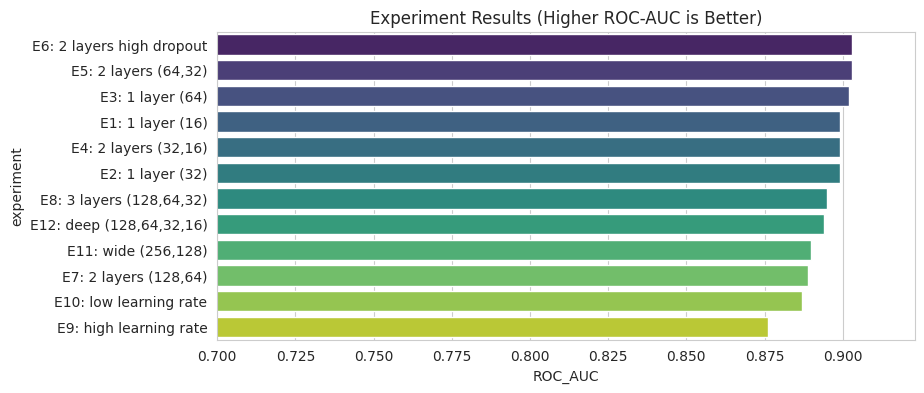

In [14]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, y="experiment", x="ROC_AUC", palette="viridis")
plt.title("Experiment Results (Higher ROC-AUC is Better)")
plt.xlim(0.7, results_df["ROC_AUC"].max() + 0.02)
plt.show()

# **9. Train the Best Model**
Now, set aside a small part of the training dataset for validation and plot the loss values to ensure that the network does indeed learn and that there is no significant overfitting. The decreasing value of training loss and low values of validation loss are good indicators here.

In [15]:
best_name = results_df.iloc[0]["experiment"]
best = [e for e in experiments if e["name"] == best_name][0]
final_model = build_model(best["layers"], best["dropout"], best["lr"])
history = final_model.fit(X_train, y_train, epochs=30, batch_size=32,
                          validation_data=(X_val, y_val), verbose=0)
print("Best Settings:", best_name)

Best Settings: E6: 2 layers high dropout


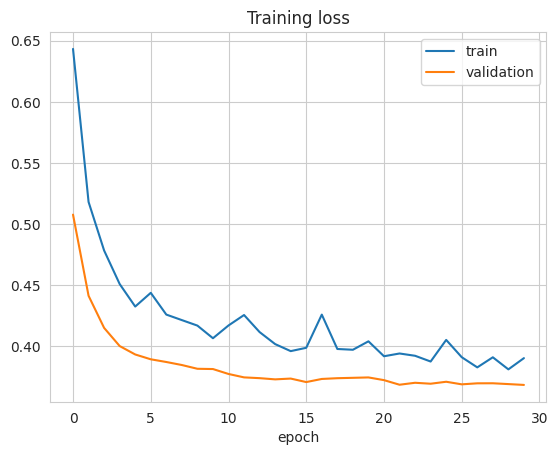

In [16]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Training loss")
plt.xlabel("epoch")
plt.legend()
plt.show()

# **10. Model Evaluation**

Running final model on the test data, which it has never seen before. To check ROC-AUC (ability of the model to rank users ahead of non-users), F1 (balance between precision and recall) as well as full classification report and a confusion matrix. Accuracy is an inappropriate metric for this slightly imbalanced yes/no problem.
Validate the model on the test set that was completely left out since the beginning of the experiments, and was not used at all until this step.

In [17]:
prob = final_model.predict(X_test, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))
print("F1:", round(f1_score(y_test, pred), 3))
print()
print(classification_report(y_test, pred, target_names=["Non-user", "User"]))

ROC-AUC: 0.858
F1: 0.844

              precision    recall  f1-score   support

    Non-user       0.69      0.65      0.67       124
        User       0.83      0.86      0.84       252

    accuracy                           0.79       376
   macro avg       0.76      0.75      0.76       376
weighted avg       0.78      0.79      0.79       376



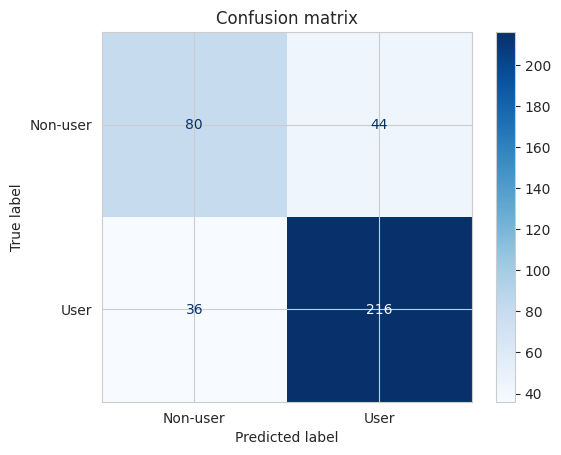

In [18]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["Non-user", "User"]).plot(cmap="Blues")
plt.title("Confusion matrix")
plt.show()

From the above shown matrix, it can get information about all four types of outcomes: true positives, true negatives and false positive and negative errors. When it comes to a screener for users, false negatives (lower left corner) are more expensive than false positives. Therefore, if necessary, the decision threshold could be lowered to include more users at the expense of some false positive results.

# **11. Features Importance**

A neural network does not give me any straightforward way to know which input features it used. Now, permutation importance will be used that is a very easy and widely used approach. This approach consists of shuffling a feature one by one in order to destroy the relation between it and the outcome and checking how the ROC-AUC score decreases. If after shuffling a certain feature the score decreases drastically, that means the feature was very important.

/tmp/ipykernel_35082/2210334146.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, y="feature", x="importance", palette="magma")


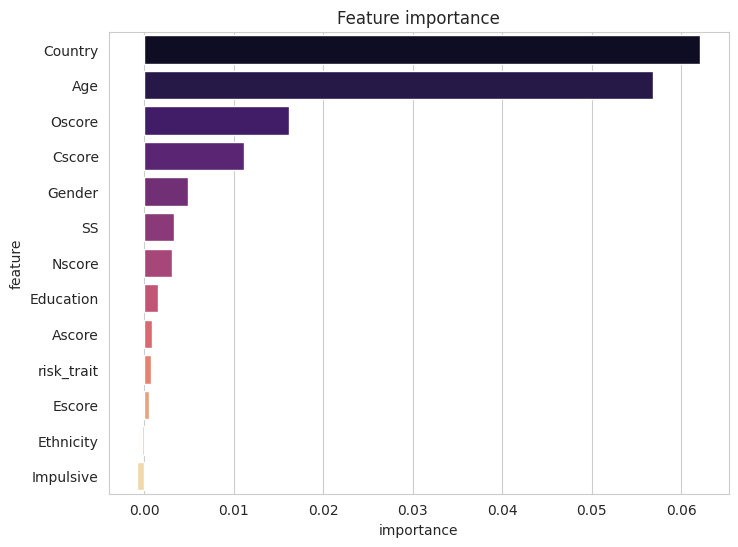

,feature,importance
3,Country,0.062116
0,Age,0.056836
7,Oscore,0.016225
9,Cscore,0.011105
1,Gender,0.004928
11,SS,0.003328
5,Nscore,0.003136
2,Education,0.001536
8,Ascore,0.000864
12,risk_trait,0.000736


In [19]:
base_score = roc_auc_score(y_test, final_model.predict(X_test, verbose=0).ravel())
importance = []
for i in range(X_test.shape[1]):
    X_shuffled = X_test.copy()
    np.random.shuffle(X_shuffled[:, i])
    score = roc_auc_score(y_test, final_model.predict(X_shuffled, verbose=0).ravel())
    importance.append(base_score - score)

imp_df = pd.DataFrame({"feature": features, "importance": importance})
imp_df = imp_df.sort_values("importance", ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(data=imp_df, y="feature", x="importance", palette="magma")
plt.title("Feature importance")
plt.show()
imp_df

The above bar graph shows the importance of different inputs. Age and country are the main predictors, followed by openness; the personality risk traits and some other inputs do not matter much.

# **12. Results of the Experiments**

A number of trends emerged after the analysis was conducted:

- **All networks were equally successful:** all twelve networks achieved similar performance(the validation ROC-AUC value ranged from about 0.87 to 0.90), thus the problem could be solved by using a small network, and none of the designs stood out. The notebook automatically selects the highest scoring network every time(shown in Section 9).
- **Larger is not better:** the addition of new layers and layers with higher width (E8, E11, E12) did not result in improved performance compared to smaller networks, thus the excess capacity is not required, and larger networks might overfit.
- **Dropout:** the change in dropout did not make any difference – no dropout, dropout of 0.2 and 0.4 yielded almost the same results, and it is an indication that the small network is not overfitting.
- **Learning rate:** the default rate of 0.001 was the most stable; the high learning rate (E9) always gave the lowest score, whereas the very low learning rate (E10) took longer to train.

In conclusion, as the scores were very close in value, there is no need for a large network and a simple robust design is best. The two most important factors were always age and country, then openness, while the risky personality traits had less influence than initially anticipated.

# **13. Summary**

For the purposes of model, neural network predicting use of cannabis based on the personality variables was created excluding all the information on the consumption of other substance(not cheating). The process involved transformation of the cannabis variable into labels, investigation of data, exclusion of the answers that were marked as not reliable because of the placebo variable and normalization of inputs. Twelve models of various design were attempted, yet all of them got scores within a narrow range, which means that small neural networks are adequate and the notebook chose the one with the highest score, which scored approximately 0.86 ROC-AUC on the test set. The most meaningful predictor was age, country and openness.
This model works efficiently as a risk score, which can help target people, who are likely to benefit from educational or support interventions, but this result should never be applied as a definitive label for anybody. There are concerns concerning self-reported data and the non-representative sample population, so the results have to be taken into account carefully. Further actions can include testing alternative models as well as validating the model using another sample population.

**Strengths:**

- There is no data leakage because only background information and personality data are considered.
- Careless respondents excluded to improve data quality.
- Tested in twelve experiments; therefore, the resulting model is evidence-based.
- Easy to understand; there are some critical factors determining the probability of an outcome.

**Limitations:**

- The data comes from self-reported surveys and can be biased.
- Not fully representative sample used.
- The definition of **user** covers both light and heavy users.
- Values after rescaling cannot be interpreted in actual numbers.

**Deployment(business recommendation):**

- Apply as a scoring mechanism to address high-risk individuals.
- Assist in making decisions but not labeling people.
- Adjust the threshold to detect more people in case required.

# **References:**

Fehrman, E., Muhammad, A.K., Mirkes, E.M., Egan, V. and Gorban, A.N. (2017) Drug consumption (quantified) data set. UCI Machine Learning Repository. Available at: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified (Accessed: 20 June 2026).